# Energy Consumption Prediction (Regression)

Machine Learning project - EFREI Paris

Dataset: PJM Hourly Energy Consumption (Kaggle, robikscube/hourly-energy-consumption)

Authors: (to fill in)

## Project goal

Predict the hourly electricity consumption (in megawatts) of the PJM grid. This is a regression problem on a time series.

## Forecasting setting used in this notebook

We predict the consumption at hour t using only information known 24 hours earlier (day-ahead forecast) plus calendar information (hour, day, month, holidays), which is known in advance. Every lag and rolling feature is therefore built from values at least 24 hours in the past. This avoids data leakage and corresponds to a realistic use case: a utility that must plan production for the next day.

## How the notebook maps to the project objectives

1. Data exploration to understand the data set and identify relevant features: steps 2 and 4
2. Data preprocessing (missing values, scaling, encoding): steps 3, 5 and 8
3. Identify whether the problem is clustering or classification: this project is a regression problem (confirmed accepted by the teacher). Step 11 (optional part) adds a classification task and a clustering task on the same data
4. Apply multiple machine learning algorithms: step 8
5. Implement and compare different metrics: step 9
6. Present findings, insights and recommendations: step 12
7. Compare methods, discuss limitations and future improvements: steps 9, 10 and 12

## How to run

1. Download the dataset from Kaggle and put the file PJME_hourly.csv next to this notebook (or change DATA_PATH below).
2. Install the libraries: pip install pandas numpy scikit-learn matplotlib seaborn lightgbm xgboost statsmodels
3. Run all cells from top to bottom. Figures are saved in the folder figures, result tables in the folder results.

## Step 1 - Imports and configuration

All the parameters that you may want to change are grouped in the cell below: the data file, the random seed and the dates that separate the training, validation and test periods.

The split is done by time and never at random. With a random split, the model would see hours that are located between training hours, and the scores would be unrealistically good.

PJME covers about August 2002 to August 2018. With the dates below: training = 2002 to 2015, validation = 2016, test = 2017 to August 2018. If you use another region file, check its date range and adapt the dates.

In [7]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from pandas.tseries.holiday import USFederalHolidayCalendar
from statsmodels.graphics.tsaplots import plot_acf

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    mean_absolute_percentage_error, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, silhouette_score,
)

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

# ---- configuration ----
DATA_PATH = "PJME_hourly.csv"
RANDOM_STATE = 42
TRAIN_END = "2015-12-31 23:00:00"
VAL_END = "2016-12-31 23:00:00"
MAX_GAP_TO_FILL = 6        # missing runs up to 6 hours are interpolated
N_SEARCH_ITER = 6          # number of hyper-parameter sets tried per model
N_CV_SPLITS = 3            # number of folds of the time-series cross-validation

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join("figures", name + ".png"), dpi=130)
    plt.show()

## Step 2 - Load the data and first inspection

We read the csv file and parse the Datetime column as real dates. The value column is called PJME_MW in this file (other regions have other names), so we rename it to MW to keep the rest of the notebook generic.

Then we look at the size of the table, the data types, the first and last rows, the date range and the basic statistics. We also check three things that are known to be a problem in this dataset: the rows are not necessarily sorted, some timestamps are duplicated, and some hours are missing.

In [8]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "File " + DATA_PATH + " not found. Download it from "
        "https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption "
        "and put it next to this notebook, or change DATA_PATH."
    )

raw = pd.read_csv(DATA_PATH, parse_dates=["Datetime"])
value_col = [c for c in raw.columns if c != "Datetime"][0]
raw = raw.rename(columns={value_col: "MW"})

print("Shape:", raw.shape)
print()
print(raw.dtypes)
print()
display(raw.head())
display(raw.tail())

Shape: (145366, 2)

Datetime    datetime64[us]
MW                 float64
dtype: object



,Datetime,MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


,Datetime,MW
145361,2018-01-01 20:00:00,44284.0
145362,2018-01-01 21:00:00,43751.0
145363,2018-01-01 22:00:00,42402.0
145364,2018-01-01 23:00:00,40164.0
145365,2018-01-02 00:00:00,38608.0


In [9]:
print("Rows sorted by date:", raw["Datetime"].is_monotonic_increasing)
print("Date range:", raw["Datetime"].min(), "->", raw["Datetime"].max())
print("Duplicated timestamps:", raw["Datetime"].duplicated().sum())
print("Missing values in MW:", raw["MW"].isna().sum())
print()
display(raw["MW"].describe().to_frame().T)

Rows sorted by date: False
Date range: 2002-01-01 01:00:00 -> 2018-08-03 00:00:00
Duplicated timestamps: 4
Missing values in MW: 0



,count,mean,std,min,25%,50%,75%,max
MW,145366.0,32080.222831,6464.012166,14544.0,27573.0,31421.0,35650.0,62009.0


## Step 3 - Data cleaning (missing values and duplicates)

We handle the problems found in step 2 one by one.

3.1 Duplicated timestamps. In this dataset they come mostly from the daylight saving time change in autumn (the same local hour happens twice). We keep one row per timestamp by averaging the duplicated values, then sort the rows by date.

3.2 Missing hours. We build the complete hourly calendar between the first and last date, and reindex the series on it. Every hour that was absent now appears as a missing value (NaN), so we can count and locate the gaps.

3.3 Filling the gaps. Short gaps (up to 6 hours) are filled by time interpolation, which is reasonable because consumption is smooth from one hour to the next. Longer gaps are not invented: they stay as NaN, and the rows that depend on them are removed later when we build the lag features.

3.4 Outliers. We flag unusual values with a robust score (distance to the median of the same weekday and hour, divided by the median absolute deviation). We only report them: real consumption peaks during heat waves or cold waves are legitimate and are exactly what the model must learn, so we only correct values that are physically impossible (zero or negative).

In [10]:
# 3.1 duplicates: one value per timestamp, sorted
series = raw.groupby("Datetime")["MW"].mean().sort_index()
print("Rows after removing duplicated timestamps:", len(series))

# 3.2 complete hourly calendar
full_index = pd.date_range(series.index.min(), series.index.max(), freq="h")
series = series.reindex(full_index)
series.index.name = "Datetime"

missing_mask = series.isna()
print("Missing hours:", int(missing_mask.sum()), "out of", len(series))

# length of each run of consecutive missing hours
run_id = (missing_mask != missing_mask.shift()).cumsum()
run_len = missing_mask.groupby(run_id).transform("sum")
gap_lengths = run_len[missing_mask].groupby(run_id[missing_mask]).first()
print("Number of gaps:", len(gap_lengths))
print("Gap length distribution (hours):")
print(gap_lengths.value_counts().sort_index())

Rows after removing duplicated timestamps: 145362
Missing hours: 30 out of 145392
Number of gaps: 30
Gap length distribution (hours):
MW
1    30
Name: count, dtype: int64


In [11]:
# 3.3 fill short gaps by time interpolation, keep long gaps as NaN
interpolated = series.interpolate(method="time")
short_gap = missing_mask & (run_len <= MAX_GAP_TO_FILL)
series_clean = series.copy()
series_clean[short_gap] = interpolated[short_gap]

print("Hours filled by interpolation:", int(short_gap.sum()))
print("Hours still missing (long gaps):", int(series_clean.isna().sum()))

# 3.4 outliers: modified z-score against the median of the same weekday and hour
tmp = series_clean.to_frame("MW")
tmp["dow"] = tmp.index.dayofweek
tmp["hour"] = tmp.index.hour
grp = tmp.groupby(["dow", "hour"])["MW"]
med = grp.transform("median")
mad = (tmp["MW"] - med).abs().groupby([tmp["dow"], tmp["hour"]]).transform("median")
mod_z = 0.6745 * (tmp["MW"] - med) / mad
print("Strong outliers (modified z-score above 6):", int((mod_z.abs() > 6).sum()))
print("Impossible values (MW <= 0):", int((series_clean <= 0).sum()))

# only physically impossible values are treated as missing
series_clean[series_clean <= 0] = np.nan

Hours filled by interpolation: 30
Hours still missing (long gaps): 0
Strong outliers (modified z-score above 6): 1
Impossible values (MW <= 0): 0


## Step 4 - Exploratory data analysis

The goal of this step is to understand the structure of the data and decide which features will be useful. We look at the series at several time scales:

4.1 The whole period, with a 30-day moving average to see the long-term trend.
4.2 A winter week and a summer week, to see the daily rhythm.
4.3 The average daily profile for each day of the week.
4.4 The distribution of consumption by month.
4.5 A heatmap of the average consumption by hour and month.
4.6 The distribution of the values.
4.7 The autocorrelation, which tells us which past hours are informative (this directly guides the choice of lag features).

For the report, write down what you observe on each graph (trend, daily cycle, weekly cycle, seasonality, spikes) and connect it to a feature built in step 5.

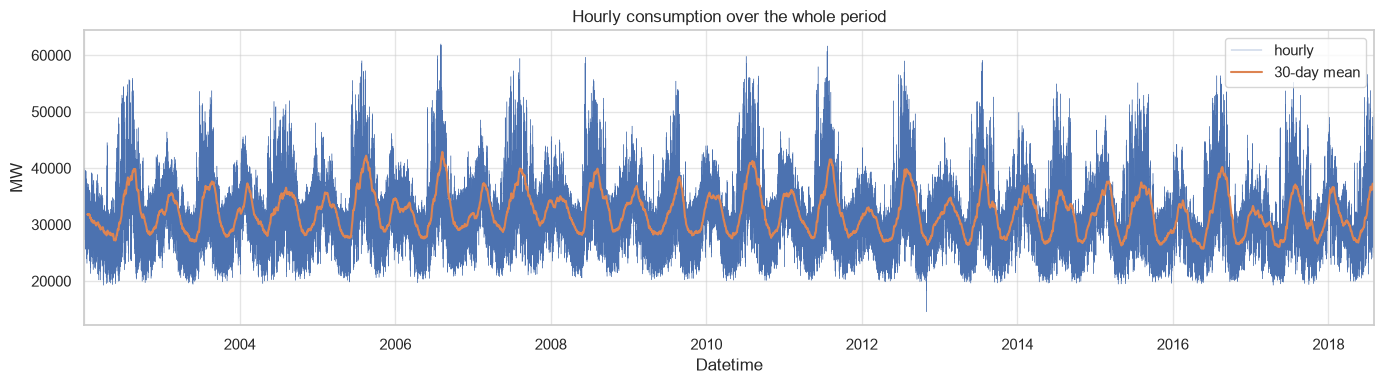

In [12]:
# 4.1 whole period
fig, ax = plt.subplots(figsize=(14, 4))
series_clean.plot(ax=ax, linewidth=0.3, label="hourly")
series_clean.rolling(24 * 30, min_periods=24 * 15).mean().plot(ax=ax, linewidth=1.5, label="30-day mean")
ax.set_title("Hourly consumption over the whole period")
ax.set_ylabel("MW")
ax.legend()
save_fig("01_full_series")

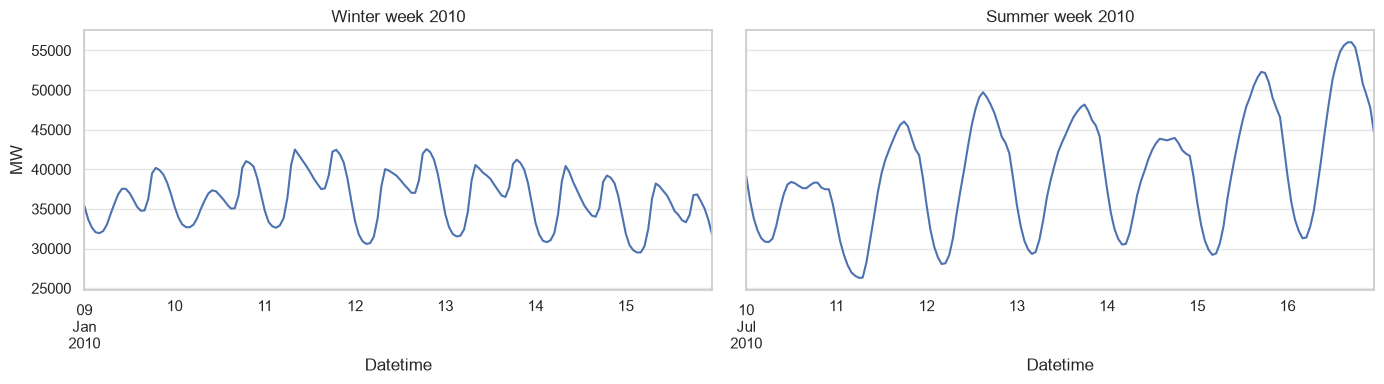

In [13]:
# 4.2 one winter week and one summer week (taken in a year in the middle of the data)
year = int(series_clean.index.year[len(series_clean) // 2])
winter = series_clean[str(year) + "-01-09":str(year) + "-01-15"]
summer = series_clean[str(year) + "-07-10":str(year) + "-07-16"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
winter.plot(ax=axes[0], title="Winter week " + str(year))
summer.plot(ax=axes[1], title="Summer week " + str(year))
axes[0].set_ylabel("MW")
save_fig("02_winter_summer_week")

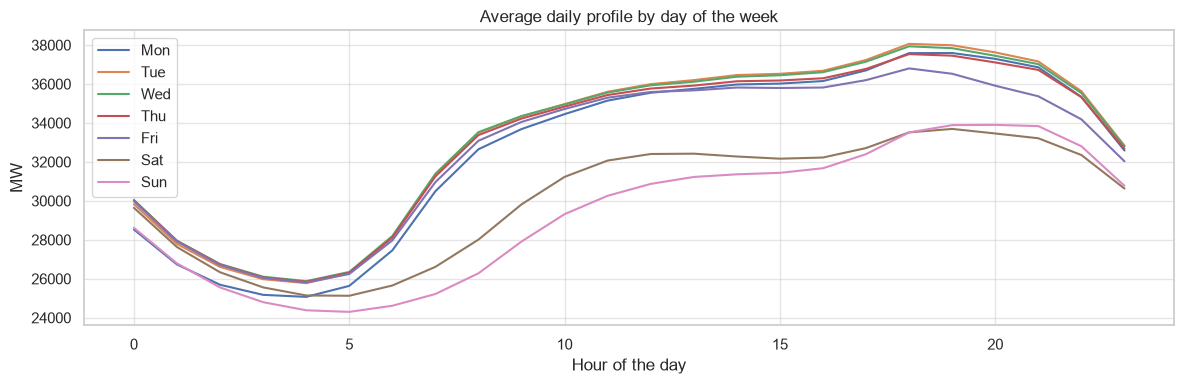

In [14]:
# 4.3 daily profile for each day of the week
eda = series_clean.to_frame("MW")
eda["hour"] = eda.index.hour
eda["dayofweek"] = eda.index.dayofweek
eda["month"] = eda.index.month
eda["year"] = eda.index.year

profile = eda.groupby(["dayofweek", "hour"])["MW"].mean().unstack(0)
profile.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
ax = profile.plot(figsize=(12, 4), title="Average daily profile by day of the week")
ax.set_ylabel("MW")
ax.set_xlabel("Hour of the day")
save_fig("03_daily_profile_by_weekday")

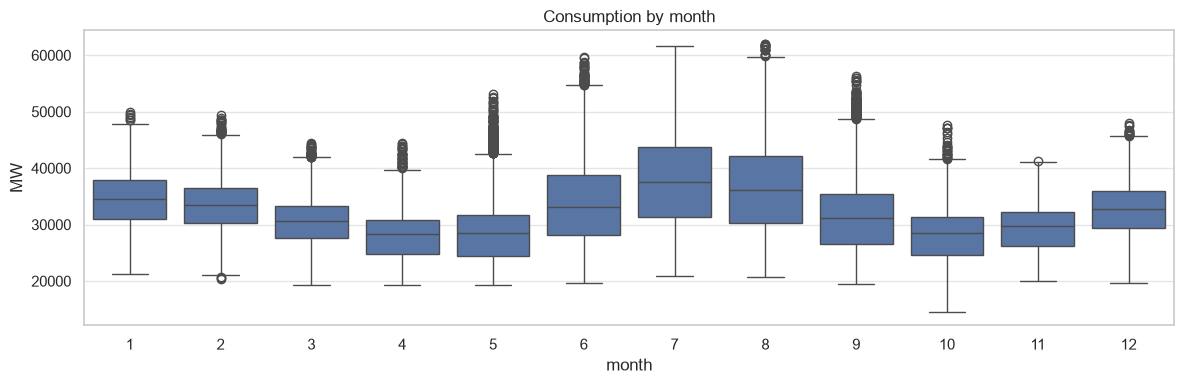

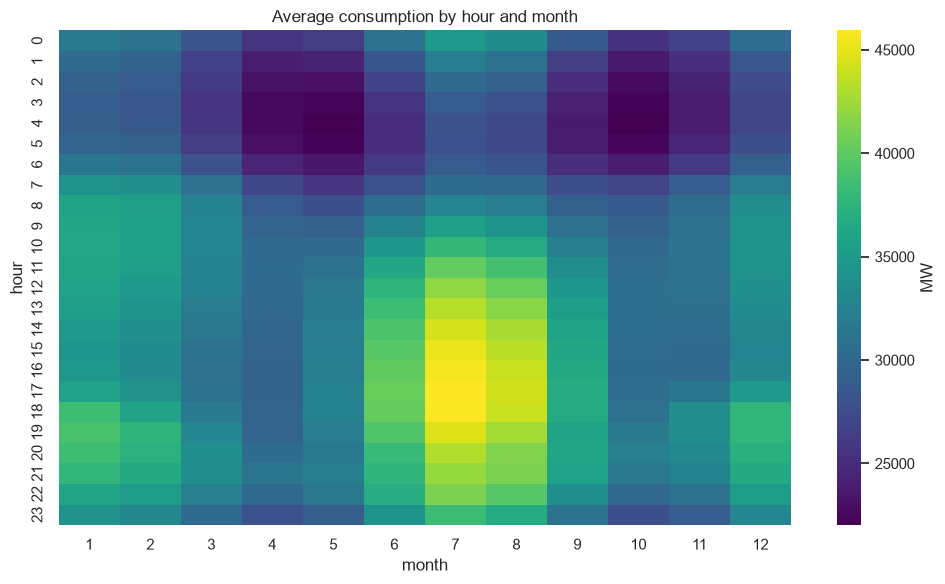

In [15]:
# 4.4 distribution by month
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=eda, x="month", y="MW", ax=ax)
ax.set_title("Consumption by month")
save_fig("04_boxplot_by_month")

# 4.5 heatmap hour x month
heat = eda.groupby(["hour", "month"])["MW"].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(heat, cmap="viridis", ax=ax, cbar_kws={"label": "MW"})
ax.set_title("Average consumption by hour and month")
save_fig("05_heatmap_hour_month")

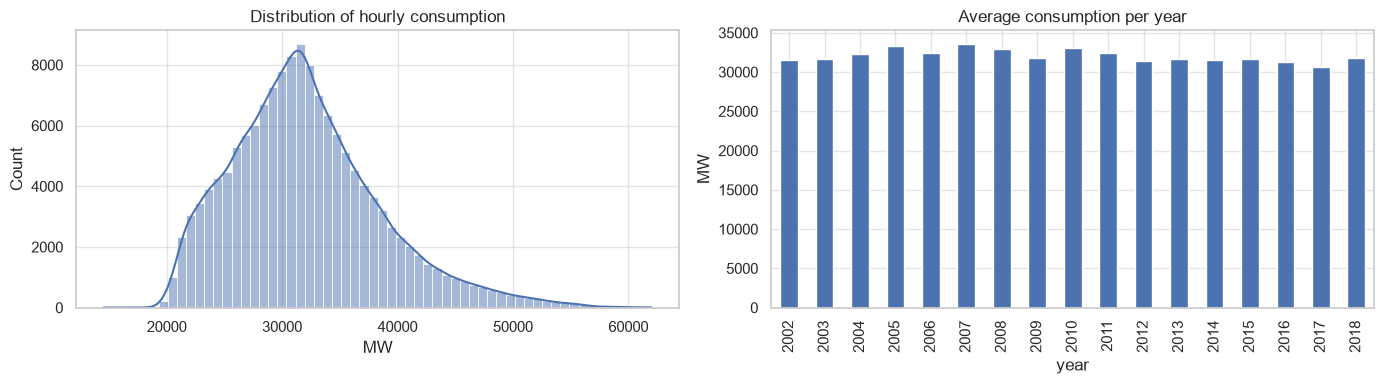

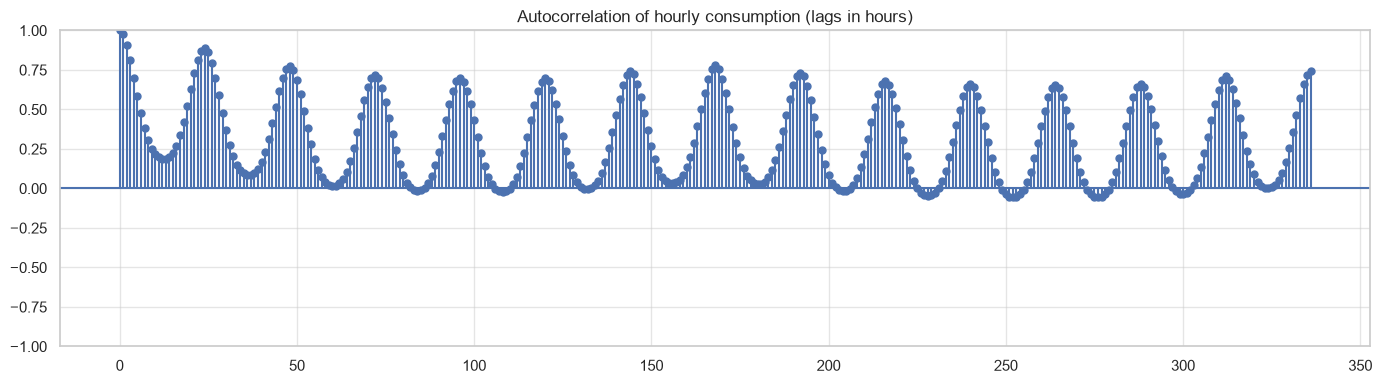

In [16]:
# 4.6 distribution of the values and yearly average
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(eda["MW"].dropna(), bins=60, kde=True, ax=axes[0])
axes[0].set_title("Distribution of hourly consumption")
eda.groupby("year")["MW"].mean().plot(kind="bar", ax=axes[1], title="Average consumption per year")
axes[1].set_ylabel("MW")
save_fig("06_distribution_and_yearly_mean")

# 4.7 autocorrelation (two weeks of lags)
fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(series_clean.dropna(), lags=24 * 14, ax=ax, alpha=None, missing="drop")
ax.set_title("Autocorrelation of hourly consumption (lags in hours)")
save_fig("07_autocorrelation")

How to read the autocorrelation graph: peaks at lag 24, 48, 72... show a daily cycle, and a higher peak at lag 168 shows a weekly cycle. That is why we will build lag features at 24, 48, 72, 168 and 336 hours.

## Step 5 - Feature engineering

A time series with only two columns cannot be used directly by a machine learning model, so we create the features from the timestamp and from the past values.

5.1 Calendar features: hour, day of week, month, day of year, quarter, week of year, weekend flag, US federal holiday flag.

5.2 Cyclical encoding: hour 23 and hour 0 are neighbours, but as numbers they are far apart. We encode hour, day of week, month and day of year with a sine and a cosine, so that the cycle is respected.

5.3 Lag features: consumption 24, 48, 72, 168 and 336 hours before (same hour yesterday, two days ago, three days ago, last week, two weeks ago). The minimum lag is 24 hours because of the day-ahead setting.

5.4 Rolling features: mean of the 24 and 168 hours that precede the lag point, and the standard deviation over 168 hours. They are computed on the series shifted by 24 hours, so they never use information that would not be available at forecasting time.

We do not use the year as a feature. Tree models cannot extrapolate: a year never seen in training (2017, 2018) would be treated like the last known year, which is useless. The long-term level is already carried by the lag features.

After building the features, the first rows (which have no history) and the rows touched by a long gap contain NaN and are removed.

In [17]:
data = series_clean.to_frame("MW")
idx = data.index

# 5.1 calendar features
data["hour"] = idx.hour
data["dayofweek"] = idx.dayofweek
data["month"] = idx.month
data["dayofyear"] = idx.dayofyear
data["quarter"] = idx.quarter
data["weekofyear"] = idx.isocalendar().week.astype(int).values
data["is_weekend"] = (idx.dayofweek >= 5).astype(int)

holidays = USFederalHolidayCalendar().holidays(start=idx.min(), end=idx.max())
data["is_holiday"] = idx.normalize().isin(holidays).astype(int)

# 5.2 cyclical encoding
data["hour_sin"] = np.sin(2 * np.pi * data["hour"] / 24)
data["hour_cos"] = np.cos(2 * np.pi * data["hour"] / 24)
data["dow_sin"] = np.sin(2 * np.pi * data["dayofweek"] / 7)
data["dow_cos"] = np.cos(2 * np.pi * data["dayofweek"] / 7)
data["month_sin"] = np.sin(2 * np.pi * data["month"] / 12)
data["month_cos"] = np.cos(2 * np.pi * data["month"] / 12)
data["doy_sin"] = np.sin(2 * np.pi * data["dayofyear"] / 365.25)
data["doy_cos"] = np.cos(2 * np.pi * data["dayofyear"] / 365.25)

# 5.3 lag features (all >= 24 hours)
for lag in [24, 48, 72, 168, 336]:
    data["lag_" + str(lag)] = data["MW"].shift(lag)

# 5.4 rolling features, computed on the series shifted by 24 hours
shifted = data["MW"].shift(24)
data["roll_mean_24"] = shifted.rolling(24).mean()
data["roll_mean_168"] = shifted.rolling(168).mean()
data["roll_std_168"] = shifted.rolling(168).std()

rows_before = len(data)
data = data.dropna()
print("Rows removed because of missing history or gaps:", rows_before - len(data))
print("Final table:", data.shape)
display(data.head())

Rows removed because of missing history or gaps: 336
Final table: (145056, 25)


,MW,hour,dayofweek,month,dayofyear,quarter,weekofyear,is_weekend,is_holiday,hour_sin,...,doy_sin,doy_cos,lag_24,lag_48,lag_72,lag_168,lag_336,roll_mean_24,roll_mean_168,roll_std_168
Datetime,,,,,,,,,,,,,,,,,,,,,
2002-01-15 01:00:00,25643.0,1,1,1,15,1,3,0,0,0.258819,...,0.255182,0.966893,26059.0,25052.0,26248.0,29445.0,30393.0,28130.458333,31478.571429,4252.105624
2002-01-15 02:00:00,24967.0,2,1,1,15,1,3,0,0,0.500000,...,0.255182,0.966893,25487.0,24007.0,25198.0,28670.0,29265.0,28192.125000,31475.660714,4256.060410
2002-01-15 03:00:00,24715.0,3,1,1,15,1,3,0,0,0.707107,...,0.255182,0.966893,25363.0,23441.0,24791.0,28375.0,28357.0,28272.208333,31474.005952,4258.395920
2002-01-15 04:00:00,24826.0,4,1,1,15,1,3,0,0,0.866025,...,0.255182,0.966893,25436.0,23129.0,24665.0,28542.0,27899.0,28368.333333,31472.636905,4260.310880
2002-01-15 05:00:00,25630.0,5,1,1,15,1,3,0,0,0.965926,...,0.255182,0.966893,26117.0,23244.0,24887.0,29261.0,28057.0,28488.041667,31471.380952,4261.867434


In [18]:
TARGET = "MW"
CAT_COLS = ["hour", "dayofweek", "month"]          # one-hot encoded for linear models
FEATURES = [c for c in data.columns if c != TARGET]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

print(len(FEATURES), "features:")
print(FEATURES)

24 features:
['hour', 'dayofweek', 'month', 'dayofyear', 'quarter', 'weekofyear', 'is_weekend', 'is_holiday', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos', 'lag_24', 'lag_48', 'lag_72', 'lag_168', 'lag_336', 'roll_mean_24', 'roll_mean_168', 'roll_std_168']


## Step 6 - Train / validation / test split (by time)

We split the table chronologically:

- Training set: used to fit the models and to tune the hyper-parameters (with a time-series cross-validation inside it).
- Validation set (one year): used to compare the tuned models with each other.
- Test set: never used for any choice. It gives the final score of each model, after the model has been refitted on training + validation.

The sets are always in the same order in time: train, then validation, then test.

,set,start,end,rows
0,train,2002-01-15 01:00:00,2015-12-31 23:00:00,122375
1,validation,2016-01-01 00:00:00,2016-12-31 23:00:00,8784
2,test,2017-01-01 00:00:00,2018-08-03 00:00:00,13897


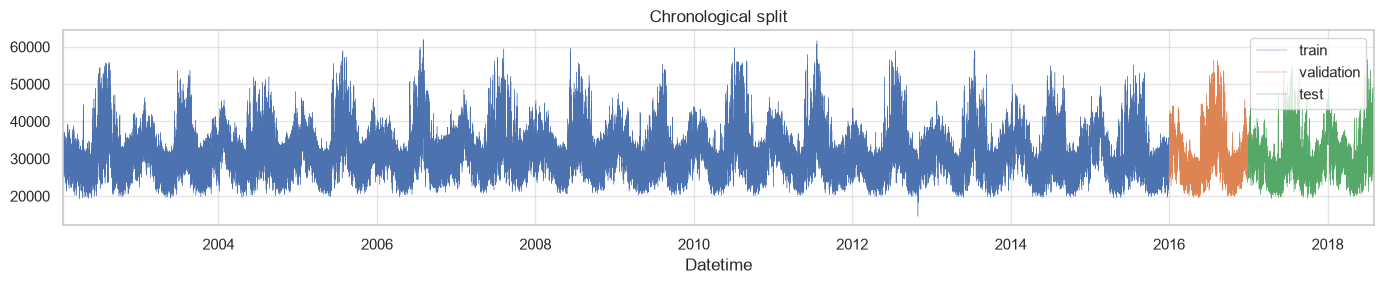

In [19]:
train = data.loc[:TRAIN_END]
val = data.loc[pd.Timestamp(TRAIN_END) + pd.Timedelta(hours=1):VAL_END]
test = data.loc[pd.Timestamp(VAL_END) + pd.Timedelta(hours=1):]
trainval = data.loc[:VAL_END]

assert len(train) > 0 and len(val) > 0 and len(test) > 0, "Check TRAIN_END and VAL_END against the date range of your file"

X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
X_trainval, y_trainval = trainval[FEATURES], trainval[TARGET]

split_table = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "start": [train.index.min(), val.index.min(), test.index.min()],
    "end": [train.index.max(), val.index.max(), test.index.max()],
    "rows": [len(train), len(val), len(test)],
})
display(split_table)

fig, ax = plt.subplots(figsize=(14, 3))
train["MW"].plot(ax=ax, linewidth=0.3, label="train")
val["MW"].plot(ax=ax, linewidth=0.3, label="validation")
test["MW"].plot(ax=ax, linewidth=0.3, label="test")
ax.legend()
ax.set_title("Chronological split")
save_fig("08_split")

## Step 7 - Baselines

Before using machine learning, we measure what very simple rules achieve:

- Naive 24h: the consumption of the same hour yesterday.
- Naive 168h: the consumption of the same hour last week (same weekday).

A machine learning model is only useful if it clearly beats these baselines.

We first define the evaluation function used everywhere in the notebook. It returns four metrics:

- MAE (mean absolute error, in MW): the average size of the error, easy to interpret.
- RMSE (root mean squared error, in MW): like MAE but it penalises large errors more, which matters for peaks.
- MAPE (mean absolute percentage error, in %): the average error relative to the real value, comparable between regions.
- R2: the share of the variance explained by the model (1 is perfect, 0 is no better than predicting the mean).

In [20]:
def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


baseline_rows = {}
for name, col in [("Baseline: same hour yesterday", "lag_24"), ("Baseline: same hour last week", "lag_168")]:
    baseline_rows[name] = {
        "val": evaluate(y_val, X_val[col]),
        "test": evaluate(y_test, X_test[col]),
    }

baseline_val = pd.DataFrame({k: v["val"] for k, v in baseline_rows.items()}).T
baseline_test = pd.DataFrame({k: v["test"] for k, v in baseline_rows.items()}).T
print("Validation set")
display(baseline_val.round(2))
print("Test set")
display(baseline_test.round(2))

Validation set


,MAE,RMSE,MAPE (%),R2
Baseline: same hour yesterday,2084.12,2863.75,6.57,0.82
Baseline: same hour last week,3323.50,4602.09,10.24,0.54


Test set


,MAE,RMSE,MAPE (%),R2
Baseline: same hour yesterday,2300.08,3134.18,7.32,0.74
Baseline: same hour last week,3511.18,4793.98,10.99,0.39


## Step 8 - Machine learning models

We compare seven regression algorithms, from the simplest to the most powerful:

1. Linear Regression: the reference linear model.
2. Ridge: linear regression with an L2 penalty that limits large coefficients.
3. Lasso: linear regression with an L1 penalty that can set useless coefficients to zero.
4. Decision Tree Regressor: one tree, easy to explain, tends to overfit.
5. Random Forest Regressor: many trees trained on random samples, averaged.
6. LightGBM: gradient boosting, trees built one after the other to correct the previous errors (technique not covered in the course).
7. XGBoost: another gradient boosting implementation (technique not covered in the course).

Preprocessing depends on the model family:

- Linear models: hour, day of week and month are one-hot encoded (a linear model cannot understand that hour 17 is a peak from the number 17 alone), and the numerical features are standardised (scaling), which is required for Ridge and Lasso penalties to treat all features fairly.
- Tree models: they work directly on the numerical features. Scaling and one-hot encoding are not needed because trees only compare values to thresholds.

Hyper-parameter tuning: for each model we try several parameter sets (random search) and score each one with a time-series cross-validation on the training set. In this cross-validation every fold trains on the past and validates on the following block, never the opposite. The criterion is the MAE.

In [21]:
def make_linear_prep():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        ("num", StandardScaler(), NUM_COLS),
    ])


def linear_pipe(estimator):
    return Pipeline([("prep", make_linear_prep()), ("model", estimator)])


models = {
    "Linear Regression": (linear_pipe(LinearRegression()), {}),
    "Ridge": (linear_pipe(Ridge()), {"model__alpha": [0.1, 1, 10, 100]}),
    "Lasso": (linear_pipe(Lasso(max_iter=5000)), {"model__alpha": [0.1, 1, 10]}),
    "Decision Tree": (
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {"max_depth": [6, 10, 14, 20], "min_samples_leaf": [5, 20, 50]},
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=150, max_samples=0.5, n_jobs=-1, random_state=RANDOM_STATE),
        {"max_depth": [10, 16, None], "min_samples_leaf": [3, 10], "max_features": [0.5, 1.0]},
    ),
    "LightGBM": (
        LGBMRegressor(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1),
        {"n_estimators": [300, 600], "learning_rate": [0.03, 0.1], "num_leaves": [31, 63], "min_child_samples": [20, 50]},
    ),
    "XGBoost": (
        XGBRegressor(tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [300, 600], "learning_rate": [0.03, 0.1], "max_depth": [4, 6, 8]},
    ),
}


def tune(estimator, grid):
    if not grid:
        return clone(estimator).fit(X_train, y_train), {}
    n_combinations = int(np.prod([len(v) for v in grid.values()]))
    search = RandomizedSearchCV(
        estimator, grid,
        n_iter=min(n_combinations, N_SEARCH_ITER),
        cv=TimeSeriesSplit(n_splits=N_CV_SPLITS),
        scoring="neg_mean_absolute_error",
        random_state=RANDOM_STATE, n_jobs=1,
    )
    search.fit(X_train, y_train)
    return search.best_estimator_, search.best_params_

Now we run the tuning for every model (this is the longest cell of the notebook, it can take several minutes). For each model we store the best parameters, the time taken and the predictions on the validation set.

In [22]:
tuned = {}
best_params = {}
val_pred = {}
val_rows = {}
fit_time = {}

for name, (estimator, grid) in models.items():
    t0 = time.time()
    best_est, params = tune(estimator, grid)
    fit_time[name] = time.time() - t0
    tuned[name] = best_est
    best_params[name] = params
    val_pred[name] = pd.Series(best_est.predict(X_val), index=X_val.index)
    val_rows[name] = evaluate(y_val, val_pred[name])
    print(name, "- done in", round(fit_time[name], 1), "s - best params:", params)

val_results = pd.DataFrame(val_rows).T
val_results["tuning time (s)"] = pd.Series(fit_time)
val_results = pd.concat([baseline_val, val_results]).sort_values("RMSE")
print()
print("Validation results (sorted by RMSE)")
display(val_results.round(2))
val_results.round(3).to_csv("results/validation_results.csv")

Linear Regression - done in 1.2 s - best params: {}
Ridge - done in 1.9 s - best params: {'model__alpha': 100}
Lasso - done in 267.4 s - best params: {'model__alpha': 10}
Decision Tree - done in 12.3 s - best params: {'min_samples_leaf': 50, 'max_depth': 10}
Random Forest - done in 153.4 s - best params: {'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 16}
LightGBM - done in 42.5 s - best params: {'num_leaves': 31, 'n_estimators': 300, 'min_child_samples': 20, 'learning_rate': 0.03}
XGBoost - done in 52.5 s - best params: {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.03}

Validation results (sorted by RMSE)


,MAE,RMSE,MAPE (%),R2,tuning time (s)
Random Forest,1641.71,2265.10,5.09,0.89,153.39
XGBoost,1650.75,2287.74,5.12,0.89,52.53
LightGBM,1666.80,2288.20,5.18,0.89,42.53
Ridge,1753.48,2354.95,5.54,0.88,1.94
Linear Regression,1754.07,2355.45,5.55,0.88,1.17
Lasso,1744.05,2359.31,5.50,0.88,267.45
Decision Tree,1801.33,2504.20,5.61,0.86,12.29
Baseline: same hour yesterday,2084.12,2863.75,6.57,0.82,NaN
Baseline: same hour last week,3323.50,4602.09,10.24,0.54,NaN


Final fit: for each model we keep the best parameters found above and refit it on training + validation (more recent data makes a better model), then score it once on the test set. The test set was not used for any decision before this point.

In [23]:
test_pred = {}
test_rows = {}
final_models = {}

for name in models:
    model = clone(tuned[name]).fit(X_trainval, y_trainval)
    final_models[name] = model
    test_pred[name] = pd.Series(model.predict(X_test), index=X_test.index)
    test_rows[name] = evaluate(y_test, test_pred[name])

test_results = pd.concat([baseline_test, pd.DataFrame(test_rows).T]).sort_values("RMSE")
print("Test results (sorted by RMSE)")
display(test_results.round(2))
test_results.round(3).to_csv("results/test_results.csv")

best_name = pd.DataFrame(test_rows).T["RMSE"].idxmin()
print("Best model on the test set:", best_name)

Test results (sorted by RMSE)


,MAE,RMSE,MAPE (%),R2
LightGBM,1868.15,2501.26,5.93,0.83
XGBoost,1870.82,2513.98,5.93,0.83
Random Forest,1869.68,2532.69,5.92,0.83
Linear Regression,1957.45,2581.47,6.26,0.82
Ridge,1957.49,2581.57,6.25,0.82
Lasso,1949.20,2581.85,6.21,0.82
Decision Tree,1972.57,2667.96,6.25,0.81
Baseline: same hour yesterday,2300.08,3134.18,7.32,0.74
Baseline: same hour last week,3511.18,4793.98,10.99,0.39


Best model on the test set: LightGBM


## Step 9 - Model comparison and error analysis

A single score hides where a model fails, so we look at the errors in several ways:

9.1 Bar chart of the metrics for all models, to compare them at a glance.
9.2 Predicted versus actual consumption for one test week.
9.3 Scatter plot of predicted versus actual values, and the distribution of the residuals (residual = actual - predicted). A good model has residuals centred on zero without a pattern.
9.4 Error by hour of the day and by month, to see in which conditions the model is less reliable.
9.5 Largest errors: the dates where the best model is the most wrong, which usually correspond to extreme weather or unusual days.

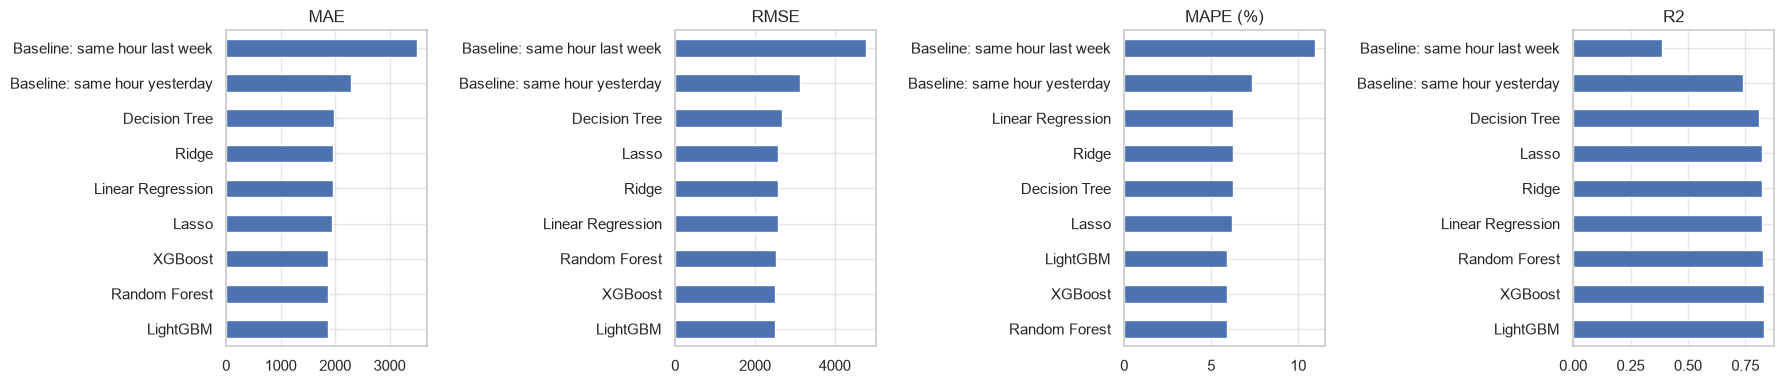

In [24]:
# 9.1 metrics comparison
metrics_to_plot = ["MAE", "RMSE", "MAPE (%)", "R2"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, m in zip(axes, metrics_to_plot):
    test_results[m].sort_values(ascending=(m != "R2")).plot(kind="barh", ax=ax, title=m)
save_fig("09_metrics_comparison")

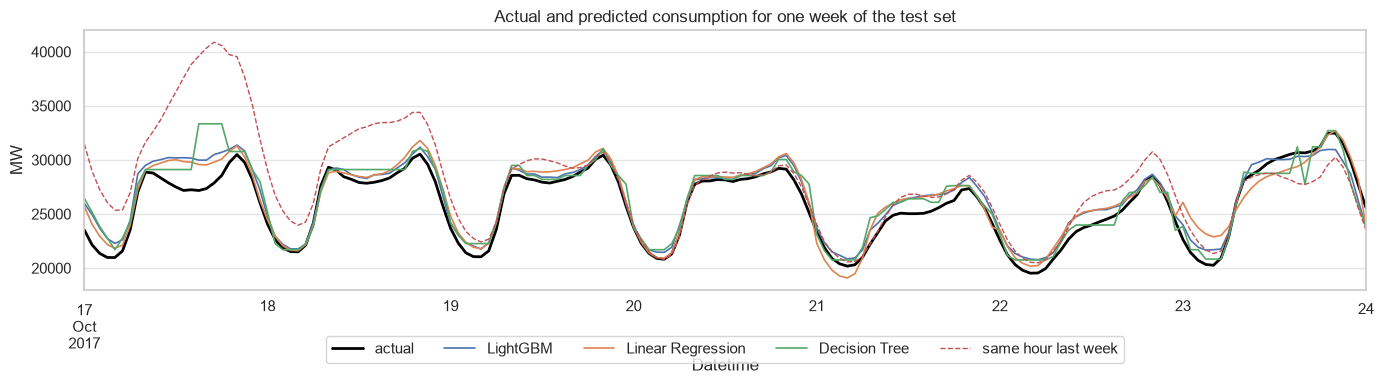

In [25]:
# 9.2 one week of the test period
start = X_test.index[len(X_test) // 2].normalize()
end = start + pd.Timedelta(days=7)
week_actual = y_test.loc[start:end]

fig, ax = plt.subplots(figsize=(14, 4))
week_actual.plot(ax=ax, color="black", linewidth=2, label="actual")
for name in list(dict.fromkeys([best_name, "Linear Regression", "Decision Tree"])):
    test_pred[name].loc[start:end].plot(ax=ax, linewidth=1.2, label=name)
test_pred_baseline = X_test["lag_168"].loc[start:end]
test_pred_baseline.plot(ax=ax, linewidth=1, linestyle="--", label="same hour last week")
ax.set_ylabel("MW")
ax.set_title("Actual and predicted consumption for one week of the test set")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5)
save_fig("10_week_prediction")

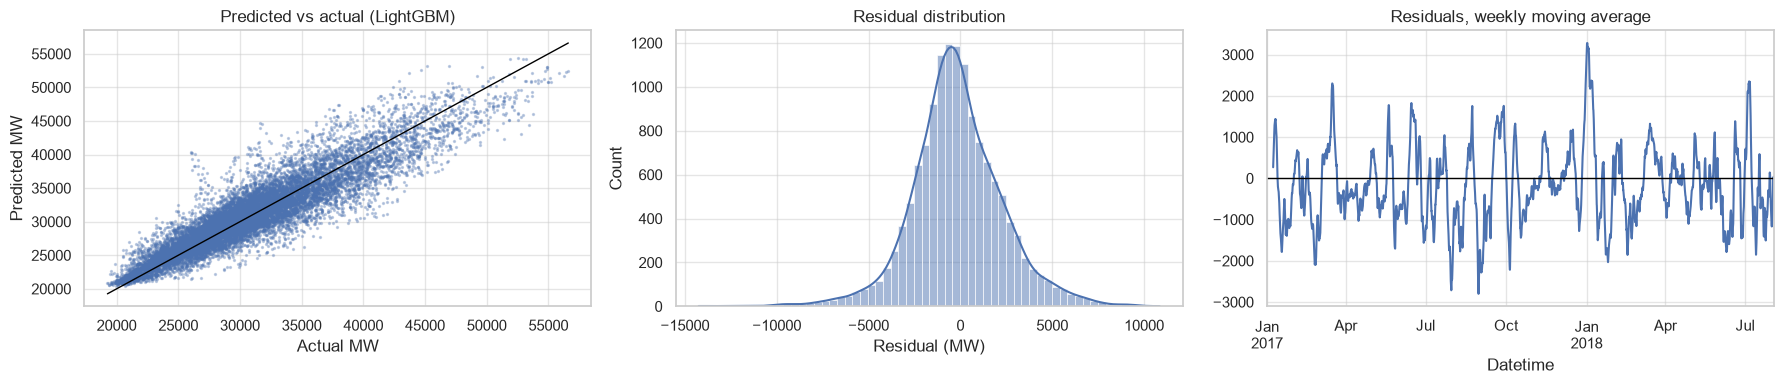

In [26]:
# 9.3 predicted vs actual, residuals
best_pred = test_pred[best_name]
residuals = y_test - best_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].scatter(y_test, best_pred, s=2, alpha=0.3)
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[0].plot(lims, lims, color="black", linewidth=1)
axes[0].set_xlabel("Actual MW")
axes[0].set_ylabel("Predicted MW")
axes[0].set_title("Predicted vs actual (" + best_name + ")")

sns.histplot(residuals, bins=60, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Residual (MW)")

residuals.rolling(24 * 7).mean().plot(ax=axes[2], title="Residuals, weekly moving average")
axes[2].axhline(0, color="black", linewidth=1)
save_fig("11_residuals")

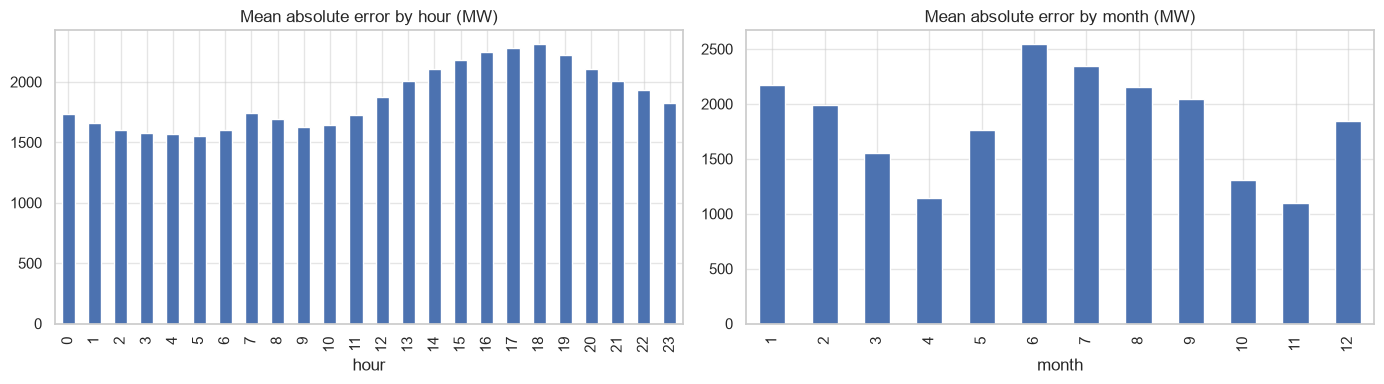

,actual,predicted,error,abs_error
Datetime,,,,
2017-05-20 16:00:00,26068.0,40317.0,-14249.0,14249.0
2017-05-20 17:00:00,26068.0,40272.0,-14204.0,14204.0
2017-05-20 18:00:00,26125.0,40237.0,-14112.0,14112.0
2017-05-20 15:00:00,26322.0,40084.0,-13762.0,13762.0
2017-05-20 19:00:00,26076.0,39340.0,-13264.0,13264.0
2017-09-06 17:00:00,31634.0,44715.0,-13081.0,13081.0
2017-09-06 16:00:00,31763.0,44518.0,-12755.0,12755.0
2017-05-20 14:00:00,26596.0,39243.0,-12647.0,12647.0
2017-09-06 18:00:00,31659.0,43992.0,-12333.0,12333.0


In [27]:
# 9.4 error by hour and by month
err = pd.DataFrame({"abs_err": residuals.abs(), "hour": residuals.index.hour, "month": residuals.index.month})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
err.groupby("hour")["abs_err"].mean().plot(kind="bar", ax=axes[0], title="Mean absolute error by hour (MW)")
err.groupby("month")["abs_err"].mean().plot(kind="bar", ax=axes[1], title="Mean absolute error by month (MW)")
save_fig("12_error_by_hour_month")

# 9.5 largest errors
worst = pd.DataFrame({"actual": y_test, "predicted": best_pred, "error": residuals})
worst["abs_error"] = worst["error"].abs()
display(worst.sort_values("abs_error", ascending=False).head(10).round(0))

## Step 10 - Feature importance

To explain the model and not only score it, we look at which features matter.

10.1 Built-in importance of the tree models (how much each feature reduces the error in the trees).
10.2 Permutation importance on the test set: we shuffle one feature at a time and measure how much the MAE gets worse. A feature that hurts the score a lot when shuffled is really used by the model. It is slower, so we use a sample of 5000 test rows.

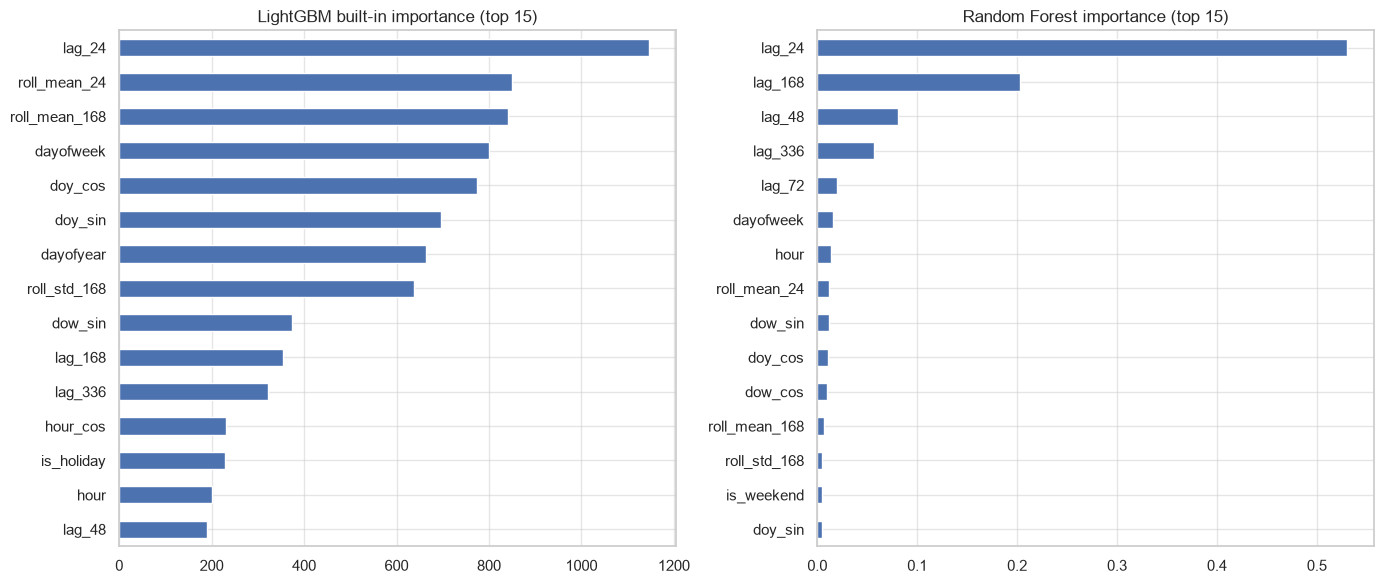

In [28]:
importance_model_name = "LightGBM"
imp_model = final_models[importance_model_name]
builtin = pd.Series(imp_model.feature_importances_, index=FEATURES).sort_values(ascending=False)

rf_imp = pd.Series(final_models["Random Forest"].feature_importances_, index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
builtin.head(15)[::-1].plot(kind="barh", ax=axes[0], title="LightGBM built-in importance (top 15)")
rf_imp.head(15)[::-1].plot(kind="barh", ax=axes[1], title="Random Forest importance (top 15)")
save_fig("13_feature_importance")

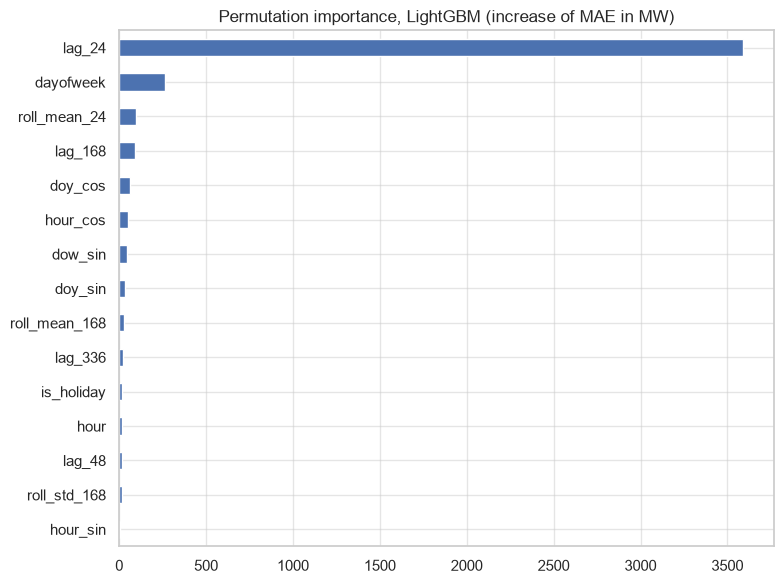

In [29]:
sample = X_test.sample(5000, random_state=RANDOM_STATE)
perm = permutation_importance(
    imp_model, sample, y_test.loc[sample.index],
    scoring="neg_mean_absolute_error", n_repeats=3, random_state=RANDOM_STATE, n_jobs=1,
)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
perm_imp.head(15)[::-1].plot(kind="barh", ax=ax, title="Permutation importance, LightGBM (increase of MAE in MW)")
save_fig("14_permutation_importance")

## Step 11 - Optional part: classification and clustering on the same data

The main project is a regression problem. The brief of the project was written for clustering and classification, so this optional part shows both on the same dataset. It is clearly separated from the main work, and if the marking scheme gives at most 3 points for the optional part, this is the content to present for it.

11.1 Classification: predict whether an hour is a high-demand hour, defined as a consumption above the 90th percentile of the training period. The features are the same as in the regression. Metrics: accuracy, precision, recall, F1 and ROC AUC. Because only 10 percent of the hours are high-demand, the classes are unbalanced, so accuracy alone would be misleading (always answering "not high" gives 90 percent), and we use class weights and look at recall and F1.

11.2 Clustering: group the days according to the shape of their 24-hour consumption curve, using K-Means. Each day is divided by its own average, so the clusters represent shapes (for example a flat weekend day versus a weekday with a strong evening peak) and not levels. The number of clusters is chosen with the silhouette score, and the clusters are then compared with the month and the weekday.

High-demand threshold (90th percentile of the training period): 40707 MW
Share of high-demand hours - train: 0.100, test: 0.079


,Accuracy,Precision,Recall,F1,ROC AUC
Logistic Regression,0.930,0.535,0.891,0.669,0.975
Random Forest,0.936,0.570,0.806,0.668,0.969


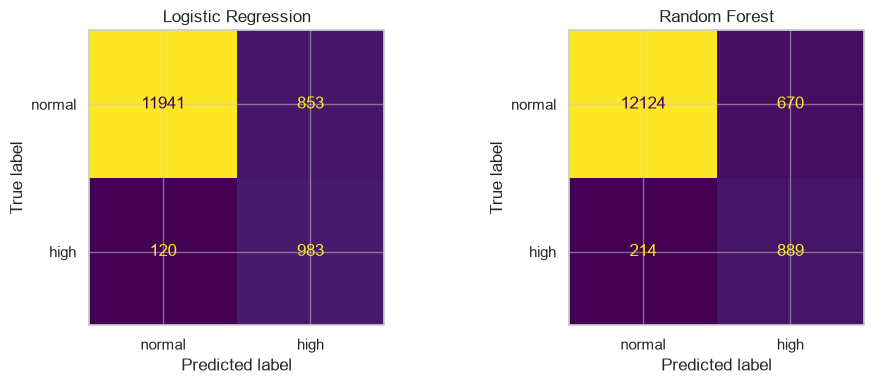

In [30]:
# 11.1 classification: high-demand hours
threshold = y_train.quantile(0.90)
print("High-demand threshold (90th percentile of the training period): %.0f MW" % threshold)

yc_train = (y_train > threshold).astype(int)
yc_trainval = (y_trainval > threshold).astype(int)
yc_test = (y_test > threshold).astype(int)
print("Share of high-demand hours - train: %.3f, test: %.3f" % (yc_train.mean(), yc_test.mean()))

classifiers = {
    "Logistic Regression": linear_pipe(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=12, min_samples_leaf=10, max_samples=0.5,
        class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE,
    ),
}

clf_rows = {}
clf_pred = {}
for name, clf in classifiers.items():
    clf.fit(X_trainval, yc_trainval)
    pred = clf.predict(X_test)
    proba = clf.predict_proba(X_test)[:, 1]
    clf_pred[name] = pred
    clf_rows[name] = {
        "Accuracy": accuracy_score(yc_test, pred),
        "Precision": precision_score(yc_test, pred),
        "Recall": recall_score(yc_test, pred),
        "F1": f1_score(yc_test, pred),
        "ROC AUC": roc_auc_score(yc_test, proba),
    }

clf_results = pd.DataFrame(clf_rows).T
display(clf_results.round(3))
clf_results.round(3).to_csv("results/classification_results.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, classifiers):
    ConfusionMatrixDisplay(confusion_matrix(yc_test, clf_pred[name]), display_labels=["normal", "high"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
save_fig("15_confusion_matrices")

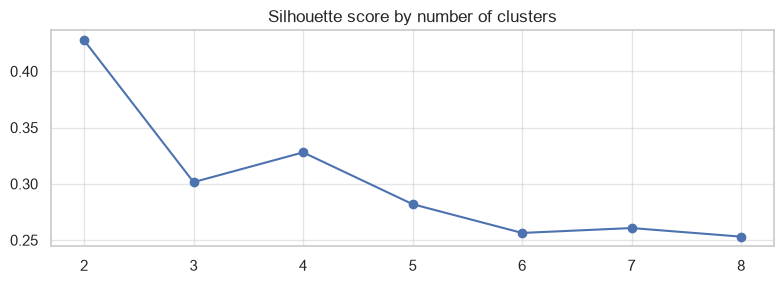

Number of clusters chosen: 2


In [31]:
# 11.2 clustering of daily load profiles
daily = series_clean.to_frame("MW")
daily["date"] = daily.index.normalize()
daily["hour"] = daily.index.hour
profiles = daily.pivot_table(index="date", columns="hour", values="MW")
profiles = profiles.dropna()                        # keep complete days only
profiles_shape = profiles.div(profiles.mean(axis=1), axis=0)

scores = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(profiles_shape)
    scores[k] = silhouette_score(profiles_shape, km.labels_, sample_size=3000, random_state=RANDOM_STATE)

pd.Series(scores).plot(marker="o", figsize=(8, 3), title="Silhouette score by number of clusters")
save_fig("16_silhouette")

best_k = max(scores, key=scores.get)
print("Number of clusters chosen:", best_k)

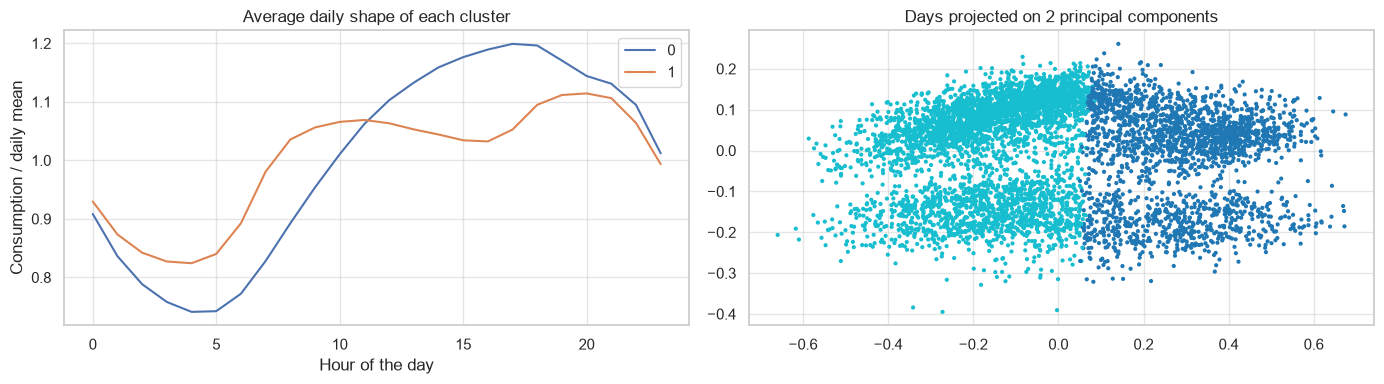

Number of days per cluster:
cluster
0    2148
1    3909
Name: count, dtype: int64

Share of weekend days in each cluster:
cluster
0    0.28
1    0.29
Name: is_weekend, dtype: float64


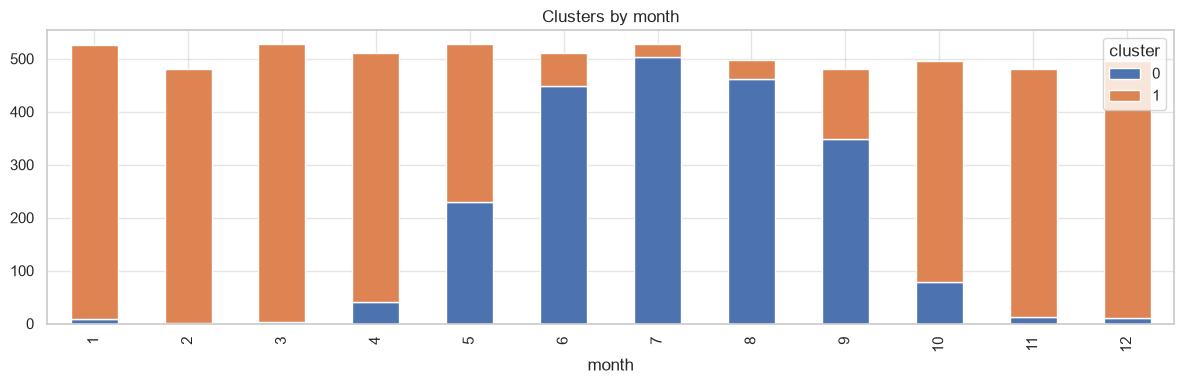

In [32]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(profiles_shape)
profiles_shape = profiles_shape.copy()
profiles_shape["cluster"] = kmeans.labels_

centers = pd.DataFrame(kmeans.cluster_centers_, columns=range(24))
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(profiles_shape.drop(columns="cluster"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
centers.T.plot(ax=axes[0], title="Average daily shape of each cluster")
axes[0].set_xlabel("Hour of the day")
axes[0].set_ylabel("Consumption / daily mean")
scatter = axes[1].scatter(coords[:, 0], coords[:, 1], c=kmeans.labels_, s=4, cmap="tab10")
axes[1].set_title("Days projected on 2 principal components")
save_fig("17_clusters")

summary = pd.DataFrame({"cluster": kmeans.labels_}, index=profiles_shape.index)
summary["month"] = summary.index.month
summary["is_weekend"] = (summary.index.dayofweek >= 5).astype(int)
print("Number of days per cluster:")
print(summary["cluster"].value_counts().sort_index())
print()
print("Share of weekend days in each cluster:")
print(summary.groupby("cluster")["is_weekend"].mean().round(2))

fig, ax = plt.subplots(figsize=(12, 4))
pd.crosstab(summary["month"], summary["cluster"]).plot(kind="bar", stacked=True, ax=ax, title="Clusters by month")
save_fig("18_clusters_by_month")

## Step 12 - Findings, recommendations, limitations and future work

Fill this section after running the notebook on the real data, using the tables and figures produced above. The numbers must come from your own results. Here is the structure to follow, with the questions each part must answer.

12.1 Main findings
- Which patterns does the consumption follow (daily cycle, weekly cycle, seasonality, trend)? Cite figures 02 to 05.
- Which model is the best on the test set and by how much does it beat the two baselines (MAE, RMSE, MAPE, R2)? Cite the test results table.
- How do the linear models, the single tree, the random forest and the two boosting models compare? Is the gain of complex models worth the extra tuning time (see the tuning time column)?
- Which features matter most (figures 13 and 14)? Does it match what you saw in the exploration?

12.2 Recommendations
- How could an energy supplier use a day-ahead forecast (production planning, purchasing, grid balancing)?
- In which hours or months should the forecast be trusted less (figure 12)? What should operators do in these situations?

12.3 Limitations
- No weather data, although temperature is the main driver of heating and cooling demand.
- A single region of the grid is modelled, and the results may differ for another region.
- The forecast horizon is fixed to 24 hours ahead; longer horizons will be less accurate.
- Large errors during unusual days (extreme weather, special events), see the largest errors table in step 9.5.
- Structural changes over the years (efficiency, population, economy) are only partly captured.
- The optional classification depends on an arbitrary threshold (90th percentile).

12.4 Areas for future improvement
- Add temperature, humidity and other weather variables.
- Add economic or calendar information (school holidays, large events).
- Try time-series specific models (SARIMA, Prophet) and neural networks (LSTM, temporal convolutional networks).
- Predict an interval and not only a point value, to measure the uncertainty.
- Repeat the pipeline on the other PJM regions and train a multi-region model.
- Shorter horizons (1 hour ahead) with more recent lags.